In [1]:
import numpy as np
import matplotlib.pyplot as plt
import modem
import adi

sdr = adi.Pluto("ip:192.168.2.1")
print("Connected")

Connected


In [2]:
samples_per_symbol = 8
rolloff = 0.35
filter_span = 10

rng = np.random.default_rng(seed=42)
bits = rng.integers(0, 2, size = 2000)

pairs = bits.reshape(-1, 2)
signed_pairs = 1 - 2 * pairs
pairs_left = signed_pairs[:, 0]
pairs_right = signed_pairs[:, 1]

QPSK_mapped = (pairs_right + 1j * pairs_left) / np.sqrt(2)

QPSK_upsampled = np.zeros(samples_per_symbol * QPSK_mapped.size, dtype=complex)
QPSK_upsampled[::samples_per_symbol] = QPSK_mapped

In [3]:
taps = modem.RRC(samples_per_symbol, rolloff, filter_span)
filtered = np.convolve(taps, QPSK_upsampled)

print("Length:", len(filtered), "| expected:", QPSK_upsampled.size + taps.size - 1)

Length: 8080 | expected: 8080


In [4]:
tail_len = len(taps) - 1
waveform = filtered[:len(QPSK_upsampled)].copy()
waveform[:tail_len] += filtered[-tail_len:]
print("Waveform Size:", waveform.size)

waveform /= np.max(np.abs(waveform))
waveform *= 2**14

Waveform Size: 8000


In [5]:
sample_rate = int(1e6)        
center_freq = int(915e6)      
buffer_size = 2 * len(waveform)          

sdr.sample_rate = sample_rate
sdr.rx_lo = center_freq
sdr.tx_lo = center_freq

sdr.tx_hardwaregain_chan0 = -30          
sdr.gain_control_mode_chan0 = "manual"   
sdr.rx_hardwaregain_chan0 = 30           

sdr.rx_buffer_size = buffer_size

In [6]:
sdr.tx_destroy_buffer()        
sdr.tx_cyclic_buffer = True   
sdr.tx(waveform)

for _ in range(5):             
    sdr.rx()

rx = sdr.rx()
print("Received samples:", rx.size)
print("Largest value:", np.max(np.abs(rx)), "(clipping if close to 2048)")

Received samples: 16000
Largest value: 107.20074626605917 (clipping if close to 2048)


Offset 0: average power = 36643.7
Offset 1: average power = 34269.7
Offset 2: average power = 31709.1
Offset 3: average power = 30461.5
Offset 4: average power = 31257.7
Offset 5: average power = 33631.2
Offset 6: average power = 36192.1
Offset 7: average power = 37440.4


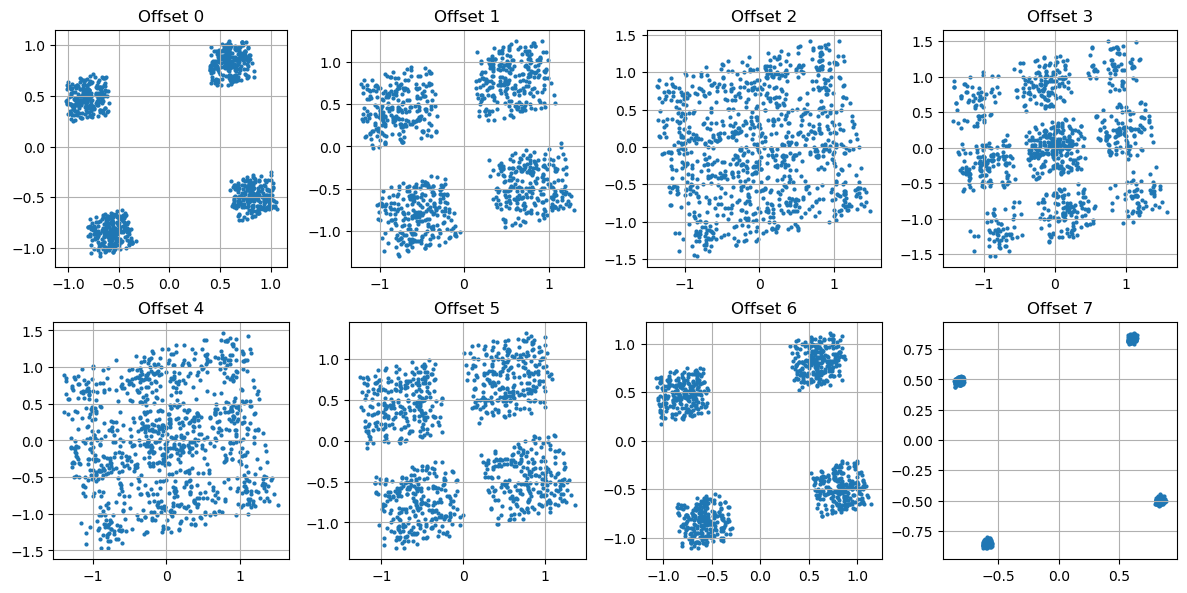

Best offset: 7


In [7]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
matched = np.convolve(rx, taps)

powers  = []
for i in range(8):
    rx_symbols = matched[200 + i::samples_per_symbol][:QPSK_mapped.size]
     
    power = np.mean(np.abs(rx_symbols) ** 2)
    print(f"Offset {i}: average power = {power:.1f}")
    powers.append(power)
    
    rx_symbols = rx_symbols / np.sqrt(power)

    ax = axes.flat[i]
    ax.scatter(rx_symbols.real, rx_symbols.imag, s=4)
    ax.set_title(f"Offset {i}")
    ax.set_aspect('equal')
    ax.grid(True)

plt.tight_layout()
plt.show()

best_offset = np.argmax(powers)
print("Best offset:", best_offset)

In [8]:
rx_symbols = matched[200 + best_offset::samples_per_symbol][:QPSK_mapped.size]
fourth_power = rx_symbols ** 4
rx_mean = -np.mean(fourth_power)
theta = np.angle(rx_mean)/4
print("Rotation:", np.degrees(theta))

corrected = rx_symbols * np.exp(-1j * theta)
corrected /= np.sqrt(np.mean(np.abs(corrected) ** 2))

Rotation: 11.628194197860758


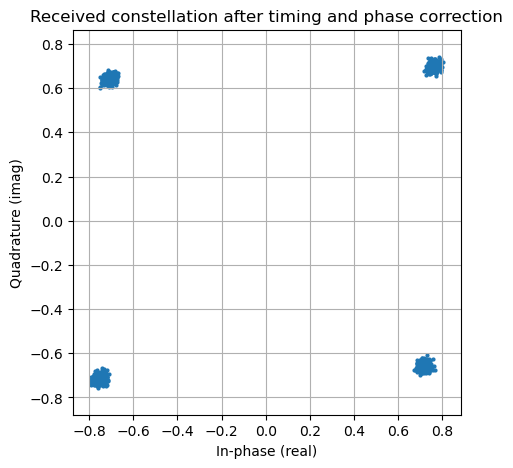

In [9]:
plt.figure(figsize=(5, 5))
plt.scatter(corrected.real, corrected.imag, s=4)
plt.axis('equal')
plt.grid(True)
plt.xlabel('In-phase (real)')
plt.ylabel('Quadrature (imag)')
plt.title('Received constellation after timing and phase correction')
plt.show()

In [10]:
sdr.tx_destroy_buffer()
print("Transmit stopped")

Transmit stopped
